# Trapezoidal and Simpson integration exercises

Two integrals are compared with their analytical values.

![](media/coursework-6ba1827cc853-6ba1827c.png)
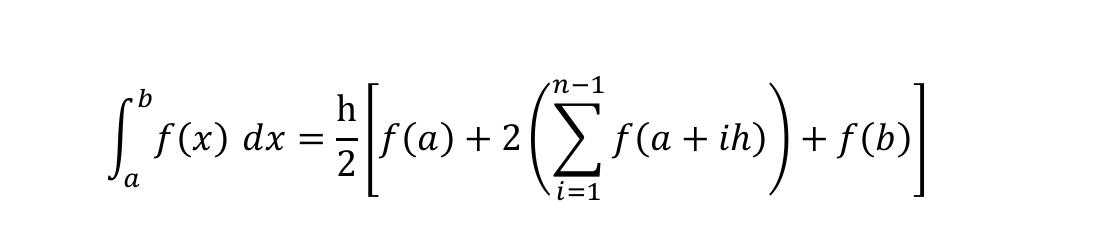

![](media/coursework-9c4847858b4c-9c484785.png)
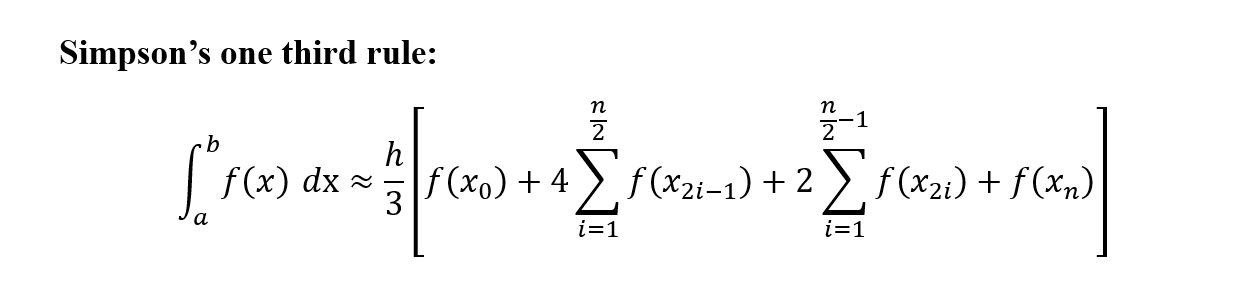

![](media/coursework-1e1a6237e6bb-1e1a6237.png)
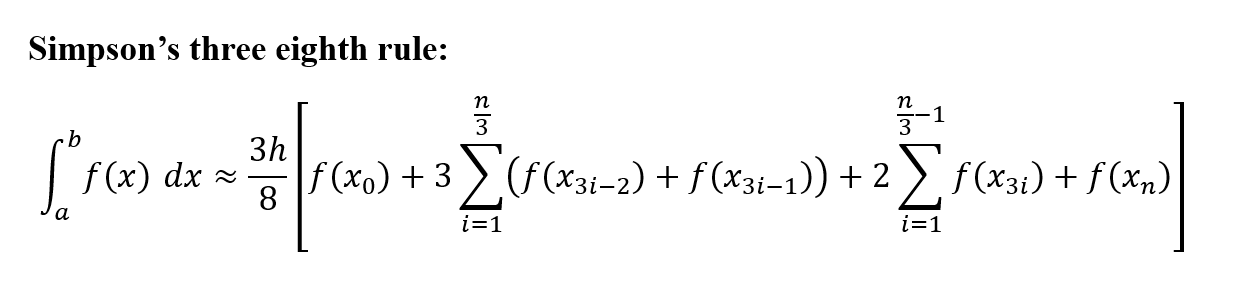

![](media/coursework-f7443f4b9f3b-f7443f4b.png)
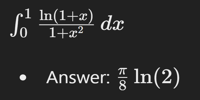

![](media/coursework-1de31b3de764-1de31b3d.png)
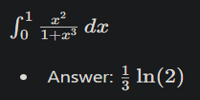

In [1]:
import numpy as np
import pandas as pd

def integrate(f, a, b, n):
    if n <= 0 or n % 6:
        raise ValueError('n must be a positive multiple of six')
    x = np.linspace(a, b, n+1)
    y = f(x)
    h = (b-a) / n
    trapezoid = h * ((y[0]+y[-1])/2 + y[1:-1].sum())
    simpson13 = h/3 * (y[0]+y[-1] + 4*y[1:-1:2].sum() + 2*y[2:-1:2].sum())
    weights = np.where(np.arange(1, n) % 3 == 0, 2, 3)
    simpson38 = 3*h/8 * (y[0]+y[-1] + weights @ y[1:-1])
    return [trapezoid, simpson13, simpson38]

examples = [
    ('log(1+x)/(1+x²)', lambda x: np.log1p(x)/(1+x*x), np.pi*np.log(2)/8),
    ('x²/(1+x³)', lambda x: x*x/(1+x**3), np.log(2)/3),
]
rows = []
for name, function, exact in examples:
    estimates = integrate(function, 0, 1, 48)
    rows.append([name, exact, *estimates])
    assert np.allclose(estimates[1:], exact, atol=1e-7)
pd.DataFrame(rows, columns=['Integrand', 'Analytical', 'Trapezoidal', 'Simpson 1/3', 'Simpson 3/8'])

,Integrand,Analytical,Trapezoidal,Simpson 1/3,Simpson 3/8
0,log(1+x)/(1+x²),0.272198,0.272159,0.272198,0.272198
1,x²/(1+x³),0.231049,0.231058,0.231049,0.231049
